# Eligo — AI engine notebook

**Eligibility-first, explainable internship matching.**
*Independent academic prototype, not affiliated with the official PM Internship Scheme portal.*

This notebook covers spec Part A (§§1–8) end to end and is meant to run top to bottom:

| Section | What happens |
|---|---|
| 3.1 | Load both public datasets, exploratory analysis, distribution charts |
| 3.2 | Cleaning and preprocessing: skill vocabulary, de-duplication **before** the split, stratified train/test split |
| 3.3 | Job-role prediction: Decision Tree vs Random Forest, evaluation, feature importance, confidence/scope analysis |
| 3.4 | Hybrid recommendation engine: eligibility gates → TF-IDF + Sentence-Transformer + skill overlap |
| 3.5 | Optional local LLM skill analysis (Ollama) with deterministic rule-based fallback |
| 3.6 | Explainable AI: explanations built only from computed values |
| 3.7 | Save artifacts + SHA-256 manifest, then a restart-safe reload test |

All logic lives in the shared `ml_core/` package; Django imports the same code, so the notebook and the web app compute the same thing.

**Data honesty.** Every number printed here comes from this run. The three student profiles in §3.4 are **DEMO / illustrative** profiles for demonstrating the engine; they are not training data. The recommender has no relevance labels, so no recommendation accuracy is claimed; a weight-sensitivity table is shown instead.

In [1]:
import json, sys, time, shutil, hashlib, warnings
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from ml_core import config as C

ART = C.ARTIFACTS_DIR
FIG = ART / "figures"
for sub in ("models", "vectorizers", "embeddings", "config", "metrics", "figures", "data"):
    (ART / sub).mkdir(parents=True, exist_ok=True)
for old in FIG.glob("*.png"):          # figures are regenerated by every run
    old.unlink()

# Eligo palette (design tokens) - navy / amber / green / orange, no rainbow
NAVY, NAVY6, NAVY1, AMBER = "#0B1F3A", "#1E3A6E", "#E8EEF8", "#D9962B"
GREEN, ORANGE, MUTED = "#1F8A5B", "#B54708", "#5B6577"
sns.set_theme(style="whitegrid", rc={"axes.edgecolor": "#E3E7EE", "axes.labelcolor": "#1A2233",
                                     "text.color": "#1A2233", "font.size": 10})
NAVY_CMAP = sns.light_palette(NAVY, as_cmap=True)

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / name, dpi=150, bbox_inches="tight")
    plt.show()
    print("saved", (FIG / name).relative_to(ROOT).as_posix())

import sklearn, sentence_transformers, torch
print("python", sys.version.split()[0], "| scikit-learn", sklearn.__version__,
      "| sentence-transformers", sentence_transformers.__version__, "| torch", torch.__version__)
print("random_state =", C.RANDOM_STATE)

D:\Internship Projects\Eligo\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


python 3.12.10 | scikit-learn 1.9.1 | sentence-transformers 6.3.0 | torch 2.15.0+cpu
random_state = 42


## 3.1 Load the datasets and explore them

| Dataset | Source | Licence | Used for |
|---|---|---|---|
| Student Career Dataset v2 | Mendeley Data, DOI 10.17632/4spj4mbpjr.2 | CC BY 4.0 | job-role labels (`Career`) from student-reported skills (`Skill`) |
| Internship Opportunities in India (2025) | Kaggle `jayaantanaath/internship-opportunities-in-india-2025` | MIT | real Internshala postings for matching |

Full column descriptions, the rejected candidates and why: `docs/DATASETS.md`.

In [2]:
RAW_JOB = C.DATA_DIR / "raw" / "mendeley_student_career" / "Career Dataset.xlsx"
RAW_INT = C.DATA_DIR / "raw" / "kaggle_internships_2025" / "merged_internships_dataset.csv"
for p in (RAW_JOB, RAW_INT):
    assert p.exists(), f"Missing {p}. See docs/DATASETS.md for the download link."

job_raw = pd.read_excel(RAW_JOB)
int_raw = pd.read_csv(RAW_INT)
for name, df in (("Student Career", job_raw), ("Internships", int_raw)):
    print(f"{name}: {df.shape[0]:,} rows x {df.shape[1]} columns")
    print("  dtypes:", df.dtypes.astype(str).to_dict())
    print("  null cells:", int(df.isna().sum().sum()), "| exact duplicate rows:", int(df.duplicated().sum()))
display(job_raw.head())
display(int_raw.head())

Student Career: 4,076 rows x 2 columns
  dtypes: {'Career': 'str', 'Skill': 'str'}


  null cells: 0 | exact duplicate rows: 1900
Internships: 8,483 rows x 13 columns
  dtypes: {'internship_id': 'str', 'Date Time': 'str', 'profile': 'str', 'company': 'str', 'Location': 'str', 'Start Date': 'str', 'Stipend': 'str', 'Duration': 'str', 'Apply by Date': 'str', 'Offer': 'str', 'Education': 'str', 'Skills': 'str', 'Perks': 'str'}
  null cells: 0 | exact duplicate rows: 0


,Career,Skill
0,Software Development and Engineering,"Web Development, Mobile App Development, Artif..."
1,Development,"Web Development, Mobile App Development, Probl..."
2,Data Science,"Data Analysis and Visualization, Deeplearning,..."
3,Development,Web Development
4,Artificial Intelligence,"Deep Learning, Machine Learning, Statistics, D..."


,internship_id,Date Time,profile,company,Location,Start Date,Stipend,Duration,Apply by Date,Offer,Education,Skills,Perks
0,2025WSHP0001,2025-09-27 20:41:17,Marketing,Arbhu Enterprises Private Limited,Bangalore,Immediately,"₹ 15,000 - 25,000 /month",3 Months,2 Oct' 25,Nothing,Not Specified,"Digital Marketing, English Proficiency (Spoken...",Not Available
1,2025WSHP0002,2025-09-21 15:41:06,Online Geography Faculty For School Kids.,Vikalp India Private Limited,Work from home,Immediately,"₹ 6,000 - 9,000 /month",6 Months,6 Oct' 25,Nothing,Not Specified,Online Teaching,Not Available
2,2025WSHP0003,2025-09-27 21:29:43,Video Editing/Making,Truevisory Realty Private Limited,Noida,Immediately,"₹ 6,000 - 8,000 /month",3 Months,15 Oct' 25,Nothing,Not Specified,"Social Media Marketing, Video Editing, Video M...","Certificate, Flexible"
3,2025WSHP0004,2025-09-27 20:18:58,Digital Marketing,Brand Scale-Up Inc,Bangalore,Immediately,"₹ 15,000 - 20,000 /month",6 Months,26 Oct' 25,Nothing,Not Specified,"English Proficiency (Spoken), English Proficie...","Certificate, Letter Of Recommendation, 5 Days ..."
4,2025WSHP0005,2025-09-27 23:04:19,Client Servicing,ABEC Limited (Asian Business Exhibitions And C...,Mumbai,Immediately,"₹ 10,000 - 15,000 /month",1 Month,2 Oct' 25,Nothing,Not Specified,English Proficiency (Spoken),Certificate


In [3]:
PLACEHOLDERS = ["Not Available", "Not Specified", "Nothing"]
placeholder_counts = {c: int(int_raw[c].isin(PLACEHOLDERS).sum()) for c in int_raw.columns}
print("Internship placeholder values ('Not Available' / 'Not Specified' / 'Nothing') per column:")
print({k: v for k, v in placeholder_counts.items() if v})
print("Scrape window:", int_raw["Date Time"].min(), "->", int_raw["Date Time"].max())
print("\nJob-role class distribution (raw rows, before de-duplication):")
print(job_raw["Career"].value_counts().to_string())

Internship placeholder values ('Not Available' / 'Not Specified' / 'Nothing') per column:
{'profile': 207, 'company': 207, 'Location': 207, 'Start Date': 275, 'Stipend': 336, 'Duration': 208, 'Apply by Date': 1260, 'Offer': 8483, 'Education': 6539, 'Skills': 213, 'Perks': 705}
Scrape window: 2025-09-21 14:37:29 -> 2025-09-28 10:11:53

Job-role class distribution (raw rows, before de-duplication):
Career
Development                                            1148
Artificial Intelligence                                 804
Software Development and Engineering                    714
Security                                                580
Data Science                                            558
User Experience (UX) and User Interface (UI) Design     272


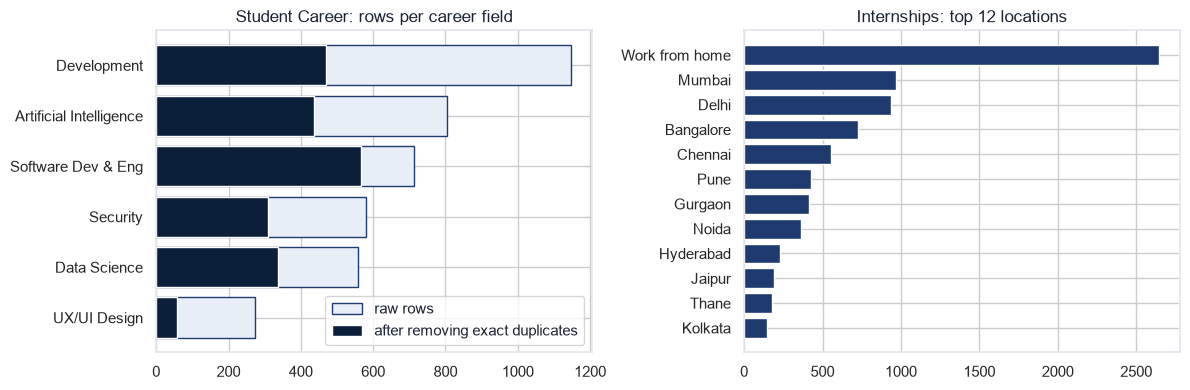

saved artifacts/figures/dist_job_role_classes.png


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
raw_counts = job_raw["Career"].value_counts()
dedup_counts = job_raw.drop_duplicates()["Career"].value_counts().reindex(raw_counts.index)
short = [c.replace("User Experience (UX) and User Interface (UI) Design", "UX/UI Design")
          .replace("Software Development and Engineering", "Software Dev & Eng") for c in raw_counts.index]
axes[0].barh(short, raw_counts.values, color=NAVY1, edgecolor=NAVY6, label="raw rows")
axes[0].barh(short, dedup_counts.values, color=NAVY, label="after removing exact duplicates")
axes[0].invert_yaxis(); axes[0].set_title("Student Career: rows per career field"); axes[0].legend()
loc = int_raw.loc[~int_raw["Location"].isin(PLACEHOLDERS), "Location"].value_counts().head(12)
axes[1].barh(loc.index, loc.values, color=NAVY6); axes[1].invert_yaxis()
axes[1].set_title("Internships: top 12 locations")
savefig("dist_job_role_classes.png")

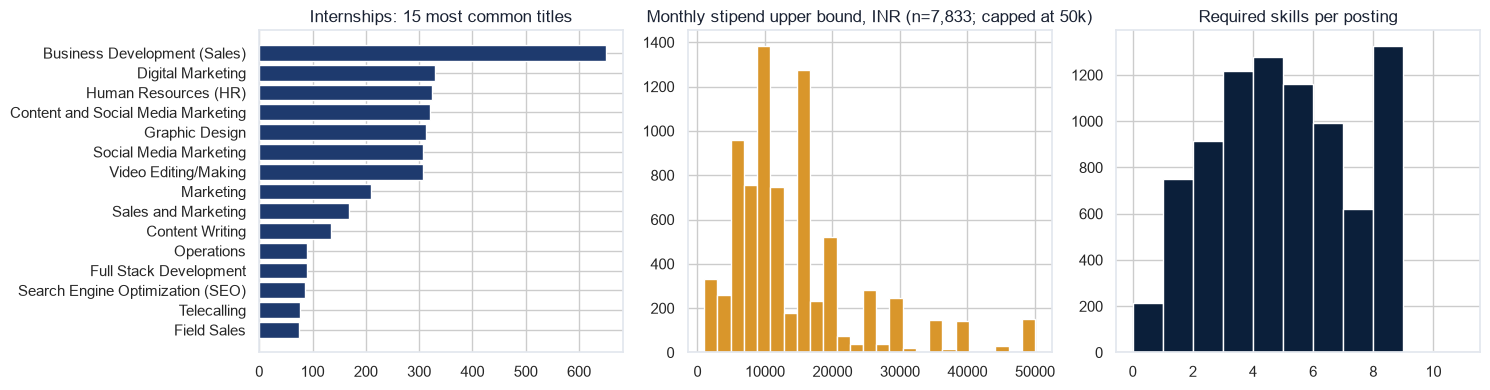

saved artifacts/figures/dist_internships.png


In [5]:
from ml_core.preprocessing import parse_stipend
from ml_core.skills import split_skills

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
titles = int_raw.loc[int_raw["profile"] != "Nothing", "profile"].value_counts().head(15)
axes[0].barh(titles.index, titles.values, color=NAVY6); axes[0].invert_yaxis()
axes[0].set_title("Internships: 15 most common titles")
monthly = [parse_stipend(s) for s in int_raw["Stipend"] if "/month" in str(s)]
mx = pd.Series([s.max_inr for s in monthly if s.max_inr]).clip(upper=50000)
axes[1].hist(mx, bins=25, color=AMBER, edgecolor="white")
axes[1].set_title(f"Monthly stipend upper bound, INR (n={len(mx):,}; capped at 50k)")
per_posting = int_raw["Skills"].map(lambda s: len(split_skills(s)))
axes[2].hist(per_posting, bins=range(0, per_posting.max() + 2), color=NAVY, edgecolor="white")
axes[2].set_title("Required skills per posting")
savefig("dist_internships.png")

## 3.2 Preprocessing (leakage-safe)

1. **One canonical skill vocabulary** for both datasets (`ml_core.skills`, D-013): split on `, ; / |`, lower-case, synonym map (`js → javascript`, `ms-excel → excel`, `ml → machine learning` …), compound tokens split (e.g. "Artificial Intelligence (AI) and Machine Learning"). Internship skills are kept as they are; student-survey tokens must appear at least twice (drops one-off typos).
2. **Job-role data**: exact duplicates removed **before** the split, then again after normalisation (so no identical row ends up in both train and test); rows with no recognised skill dropped.
3. **Stratified 80/20 split** with a fixed `random_state`. The skill encoder (`SkillBinarizer`) lives **inside** the sklearn `Pipeline`, so its vocabulary is learned from the training split only.
4. **Internships** cleaned with the documented rules in `docs/DATASETS.md` / D-007 (dropped rows, parsed stipend/duration/deadline, qualification derived from `Education`, composed description flagged `description_derived`).

In [6]:
from collections import Counter
from ml_core.skills import BASE_SYNONYMS, SkillVocab, expand_skill, normalise_skill
from ml_core.preprocessing import clean_job_role_data, clean_internships

job_tokens = [split_skills(s) for s in job_raw["Skill"]]
int_tokens = [split_skills(s) for s in int_raw["Skills"]]
v_int = SkillVocab.build(int_tokens, BASE_SYNONYMS, min_count=1)
v_job = SkillVocab.build(job_tokens, BASE_SYNONYMS, min_count=2)
vocab = SkillVocab(v_int.canonical | v_job.canonical, dict(BASE_SYNONYMS))
print(f"Canonical skills: {len(vocab.canonical):,} (internships {len(v_int.canonical):,}, "
      f"student survey {len(v_job.canonical):,}, shared {len(v_int.canonical & v_job.canonical):,})")

merges = Counter()
for toks in job_tokens + int_tokens:
    for t in toks:
        raw = " ".join(str(t).lower().split()).strip(" .,;:-_'\"()[]")
        for s in expand_skill(t, BASE_SYNONYMS):
            if s != raw:
                merges[f"{raw} -> {s}"] += 1
print("\n30 most frequent synonym/compound merges (for review):")
for k, v in merges.most_common(30):
    print(f"  {v:5d}  {k}")
vocab.to_json(ART / "config" / "skills_vocab.json")

Canonical skills: 1,068 (internships 796, student survey 324, shared 52)



30 most frequent synonym/compound merges (for review):
   2548  english proficiency (spoken -> english proficiency (spoken)
   2015  english proficiency (written -> english proficiency (written)
   1439  ms-excel -> excel
    988  data analysis and visualization -> data analysis
    988  data analysis and visualization -> data visualization
    842  ms-office -> ms office
    606  search engine optimization (seo -> search engine optimization (seo)
    585  artificial intelligence (ai) and machine learning -> artificial intelligence
    585  artificial intelligence (ai) and machine learning -> machine learning
    484  artificial intelligence (ai -> artificial intelligence (ai)
    320  hindi proficiency (spoken -> hindi proficiency (spoken)
    305  ms-word -> word
    272  search engine marketing (sem -> search engine marketing (sem)
    243  client relationship management (crm -> client relationship management (crm)
    229  ms-powerpoint -> powerpoint
     66  artificial intelligen

In [7]:
from sklearn.model_selection import train_test_split

n_raw = len(job_raw); n_exact = len(job_raw.drop_duplicates())
jobs = clean_job_role_data(job_raw, vocab)
print(f"Student Career rows: raw {n_raw:,} -> exact duplicates removed {n_exact:,} "
      f"-> normalised + de-duplicated + rows without known skills dropped {len(jobs):,}")
print(jobs["career"].value_counts().to_string())

X = jobs["skills"].tolist()
y = jobs["career"].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=C.RANDOM_STATE)
print(f"\ntrain {len(X_train):,} | test {len(X_test):,}")
train_keys = {tuple(x) for x in X_train}
print("identical skill-sets present in both train and test (different labels only):",
      sum(tuple(x) in train_keys for x in X_test))

Student Career rows: raw 4,076 -> exact duplicates removed 2,176 -> normalised + de-duplicated + rows without known skills dropped 1,868
career
Software Development and Engineering                   537
Development                                            373
Artificial Intelligence                                370
Data Science                                           286
Security                                               263
User Experience (UX) and User Interface (UI) Design     39

train 1,494 | test 374
identical skill-sets present in both train and test (different labels only): 7


In [8]:
interns = clean_internships(int_raw, vocab)
dropped_no_title = int((int_raw["profile"] == "Nothing").sum())
dropped_shifted = int(((int_raw["profile"] != "Nothing") & (int_raw["Start Date"].astype(str).str.len() > 40)).sum())
print(f"Internships: {len(int_raw):,} raw -> {len(interns):,} clean "
      f"(dropped {dropped_no_title} without a title, {dropped_shifted} with shifted columns)")
print("\nRequired qualification after the D-007 rules:")
print(interns["required_qualification"].value_counts().to_string())
print("\nspecialisation = CSE:", int((interns["specialization"] == "CSE").sum()),
      "| no required skills:", int((interns["required_skills"].map(len) == 0).sum()),
      "| no deadline:", int(interns["application_deadline"].isna().sum()),
      "| duration unknown:", int(interns["duration_months"].isna().sum()))

to_save = interns.copy()
for col in ("required_skills", "derived_fields"):
    to_save[col] = to_save[col].map(json.dumps)
to_save["application_deadline"] = to_save["application_deadline"].map(lambda d: d.isoformat() if d else "")
to_save.to_csv(ART / "data" / "internships_clean.csv", index=False, encoding="utf-8")
display(interns[["source_id", "internship_title", "company_name", "required_qualification", "required_skills",
                 "stipend_text", "application_deadline"]].head(8))

Internships: 8,483 raw -> 8,207 clean (dropped 207 without a title, 69 with shifted columns)

Required qualification after the D-007 rules:
required_qualification
Any Graduate        7966
MBA                   71
Diploma               55
Any Postgraduate      49
B.Tech                32
LLB                   10
BBA                    9
M.Tech                 4
B.Sc                   3
B.Des                  2
B.Com                  2
M.Sc                   2
MCA                    2

specialisation = CSE: 107 | no required skills: 6 | no deadline: 1052 | duration unknown: 37


,source_id,internship_title,company_name,required_qualification,required_skills,stipend_text,application_deadline
0,2025WSHP0001,Marketing,Arbhu Enterprises Private Limited,Any Graduate,"[digital marketing, english proficiency (spoke...","₹ 15,000 - 25,000 /month",2025-10-02
1,2025WSHP0002,Online Geography Faculty For School Kids.,Vikalp India Private Limited,Any Graduate,[online teaching],"₹ 6,000 - 9,000 /month",2025-10-06
2,2025WSHP0003,Video Editing/Making,Truevisory Realty Private Limited,Any Graduate,"[social media marketing, video editing, video ...","₹ 6,000 - 8,000 /month",2025-10-15
3,2025WSHP0004,Digital Marketing,Brand Scale-Up Inc,Any Graduate,"[english proficiency (spoken), english profici...","₹ 15,000 - 20,000 /month",2025-10-26
4,2025WSHP0005,Client Servicing,ABEC Limited (Asian Business Exhibitions And C...,Any Graduate,[english proficiency (spoken)],"₹ 10,000 - 15,000 /month",2025-10-02
5,2025WSHP0006,Audio Description (Music Background),Achieve Point Private Limited,Any Graduate,"[music, music production]","₹ 6,000 - 12,000 /month",2025-10-12
6,2025WSHP0007,Telecalling,Raja Tyagi,Any Graduate,"[english proficiency (spoken), english profici...","₹ 5,000 - 8,000 /month",2025-10-09
7,2025WSHP0008,New Initiative,Taskify,Any Graduate,"[marketing, strategy]","₹ 20,000 - 30,000 /month",2025-10-18


## 3.3 Job-role prediction: Decision Tree vs Random Forest

Input = canonical skills only (D-005, D-008: the public training data has no academic or assessment columns).
Both models are tuned with `GridSearchCV` (5-fold stratified CV, macro-F1) **on the training split only**, then evaluated once on the held-out test split. The best model is chosen by test macro-F1 (tie → Random Forest).

In [9]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from ml_core.skills import SkillBinarizer

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=C.RANDOM_STATE)
searches = {
    "DecisionTreeClassifier": GridSearchCV(
        Pipeline([("skills", SkillBinarizer()), ("clf", DecisionTreeClassifier(random_state=C.RANDOM_STATE))]),
        {"clf__max_depth": [None, 10, 20], "clf__min_samples_leaf": [1, 2, 5], "skills__min_count": [1, 2]},
        cv=cv, scoring="f1_macro"),
    "RandomForestClassifier": GridSearchCV(
        Pipeline([("skills", SkillBinarizer()),
                  ("clf", RandomForestClassifier(random_state=C.RANDOM_STATE, n_jobs=-1))]),
        {"clf__n_estimators": [200, 400], "clf__max_depth": [None, 20], "clf__min_samples_leaf": [1, 2],
         "skills__min_count": [1, 2]},
        cv=cv, scoring="f1_macro"),
}
for name, search in searches.items():
    t = time.time()
    search.fit(X_train, y_train)
    print(f"{name}: best CV macro-F1 {search.best_score_:.4f} with {search.best_params_} ({time.time() - t:.0f}s)")

DecisionTreeClassifier: best CV macro-F1 0.8410 with {'clf__max_depth': None, 'clf__min_samples_leaf': 1, 'skills__min_count': 1} (1s)


RandomForestClassifier: best CV macro-F1 0.8949 with {'clf__max_depth': None, 'clf__min_samples_leaf': 2, 'clf__n_estimators': 200, 'skills__min_count': 2} (33s)


In [10]:
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, confusion_matrix,
                             classification_report)

classes = sorted(set(y))
metrics, reports, cms = {}, {}, {}
for name, search in searches.items():
    model = search.best_estimator_
    pred = model.predict(X_test)
    p_m, r_m, f_m, _ = precision_recall_fscore_support(y_test, pred, average="macro", zero_division=0)
    p_w, r_w, f_w, _ = precision_recall_fscore_support(y_test, pred, average="weighted", zero_division=0)
    metrics[name] = {"accuracy": accuracy_score(y_test, pred),
                     "precision_macro": p_m, "recall_macro": r_m, "f1_macro": f_m,
                     "precision_weighted": p_w, "recall_weighted": r_w, "f1_weighted": f_w,
                     "cv_best_f1_macro": search.best_score_, "best_params": search.best_params_,
                     "n_features": int(len(model.named_steps["skills"].vocabulary_))}
    reports[name] = classification_report(y_test, pred, labels=classes, digits=3, zero_division=0)
    cms[name] = confusion_matrix(y_test, pred, labels=classes)
    print(f"=== {name} (test set, n={len(y_test)}) ===")
    print(reports[name])

table = pd.DataFrame(metrics).T[["accuracy", "precision_macro", "recall_macro", "f1_macro",
                                 "precision_weighted", "recall_weighted", "f1_weighted", "cv_best_f1_macro"]]
display(table.astype(float).round(4))

=== DecisionTreeClassifier (test set, n=374) ===
                                                     precision    recall  f1-score   support

                            Artificial Intelligence      0.797     0.851     0.824        74
                                       Data Science      0.823     0.895     0.857        57
                                        Development      0.822     0.800     0.811        75
                                           Security      0.907     0.925     0.916        53
               Software Development and Engineering      0.856     0.776     0.814       107
User Experience (UX) and User Interface (UI) Design      0.889     1.000     0.941         8

                                           accuracy                          0.840       374
                                          macro avg      0.849     0.874     0.860       374
                                       weighted avg      0.840     0.840     0.839       374

=== RandomForestCl

,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,cv_best_f1_macro
DecisionTreeClassifier,0.8396,0.8490,0.8744,0.8604,0.8404,0.8396,0.8389,0.8410
RandomForestClassifier,0.8904,0.9108,0.9133,0.9107,0.8925,0.8904,0.8898,0.8949


Best model by test macro-F1: RandomForestClassifier (0.9107)


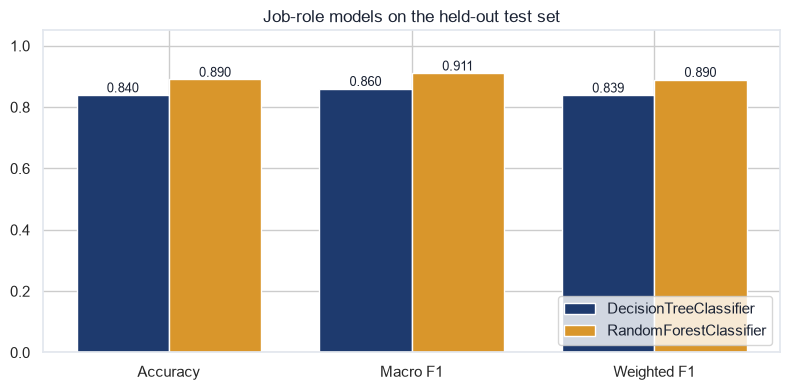

saved artifacts/figures/model_comparison.png


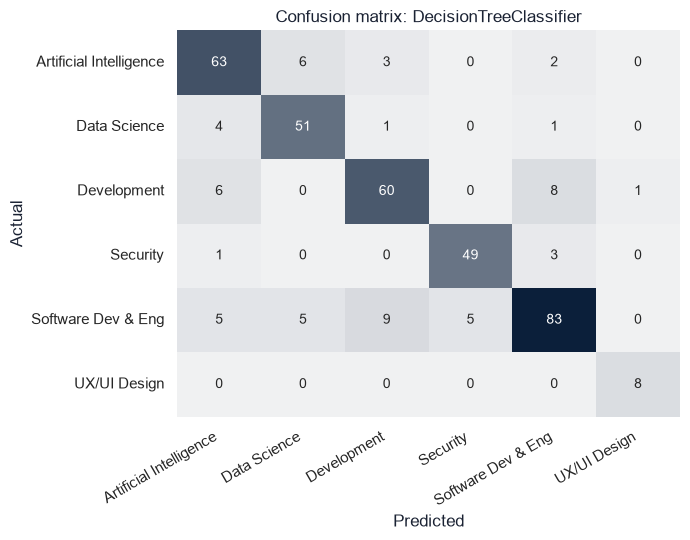

saved artifacts/figures/confusion_matrix_dt.png


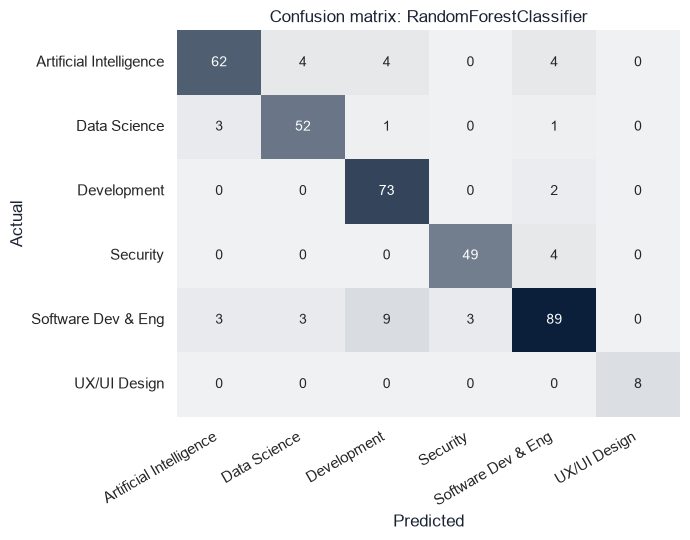

saved artifacts/figures/confusion_matrix_rf.png


In [11]:
f1 = {n: m["f1_macro"] for n, m in metrics.items()}
best_name = max(f1, key=lambda n: (round(f1[n], 6), n == "RandomForestClassifier"))
best_model = searches[best_name].best_estimator_
print(f"Best model by test macro-F1: {best_name} ({f1[best_name]:.4f})")

fig, ax = plt.subplots(figsize=(8, 4))
cols = ["accuracy", "f1_macro", "f1_weighted"]
x = np.arange(len(cols)); w = 0.38
for i, (name, colour) in enumerate((("DecisionTreeClassifier", NAVY6), ("RandomForestClassifier", AMBER))):
    vals = [metrics[name][c] for c in cols]
    bars = ax.bar(x + (i - 0.5) * w, vals, w, label=name, color=colour)
    ax.bar_label(bars, fmt="%.3f", fontsize=9)
ax.set_xticks(x, ["Accuracy", "Macro F1", "Weighted F1"]); ax.set_ylim(0, 1.05)
ax.set_title("Job-role models on the held-out test set"); ax.legend(loc="lower right")
savefig("model_comparison.png")

short = [c.replace("User Experience (UX) and User Interface (UI) Design", "UX/UI Design")
          .replace("Software Development and Engineering", "Software Dev & Eng") for c in classes]
for name, fname in (("DecisionTreeClassifier", "confusion_matrix_dt.png"), ("RandomForestClassifier", "confusion_matrix_rf.png")):
    fig, ax = plt.subplots(figsize=(7, 5.5))
    sns.heatmap(cms[name], annot=True, fmt="d", cmap=NAVY_CMAP, xticklabels=short, yticklabels=short, ax=ax, cbar=False)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(f"Confusion matrix: {name}")
    plt.xticks(rotation=30, ha="right")
    savefig(fname)

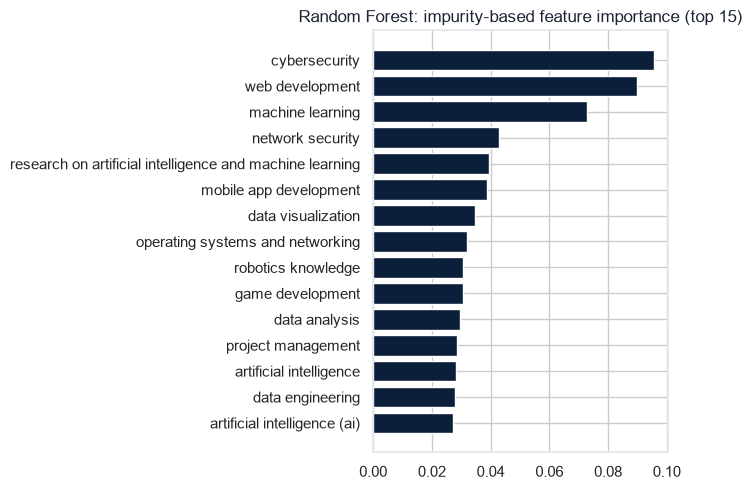

saved artifacts/figures/feature_importance_rf.png


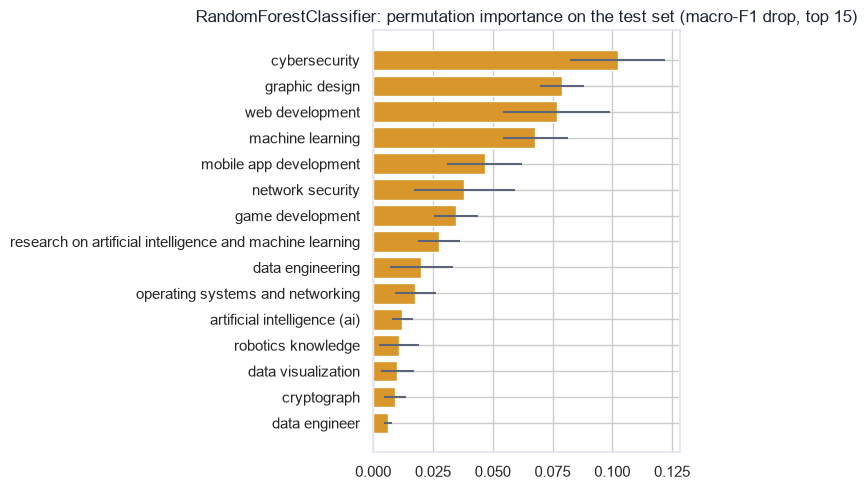

saved artifacts/figures/permutation_importance_best.png


In [12]:
from sklearn.inspection import permutation_importance
from ml_core.job_role import global_feature_importance

rf_model = searches["RandomForestClassifier"].best_estimator_
rf_top = global_feature_importance(rf_model, top_k=15)
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh([n.removeprefix("skill__") for n, _ in rf_top][::-1], [v for _, v in rf_top][::-1], color=NAVY)
ax.set_title("Random Forest: impurity-based feature importance (top 15)")
savefig("feature_importance_rf.png")

Xt_test = best_model[:-1].transform(X_test)
perm = permutation_importance(best_model[-1], Xt_test, y_test, n_repeats=10, random_state=C.RANDOM_STATE,
                              scoring="f1_macro", n_jobs=1)
names = best_model[:-1].get_feature_names_out()
order = np.argsort(perm.importances_mean)[::-1][:15]
perm_top = [(str(names[i]).removeprefix("skill__"), float(perm.importances_mean[i]), float(perm.importances_std[i]))
            for i in order]
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh([n for n, _, _ in perm_top][::-1], [m for _, m, _ in perm_top][::-1],
        xerr=[s for _, _, s in perm_top][::-1], color=AMBER, ecolor=MUTED)
ax.set_title(f"{best_name}: permutation importance on the test set (macro-F1 drop, top 15)")
savefig("permutation_importance_best.png")

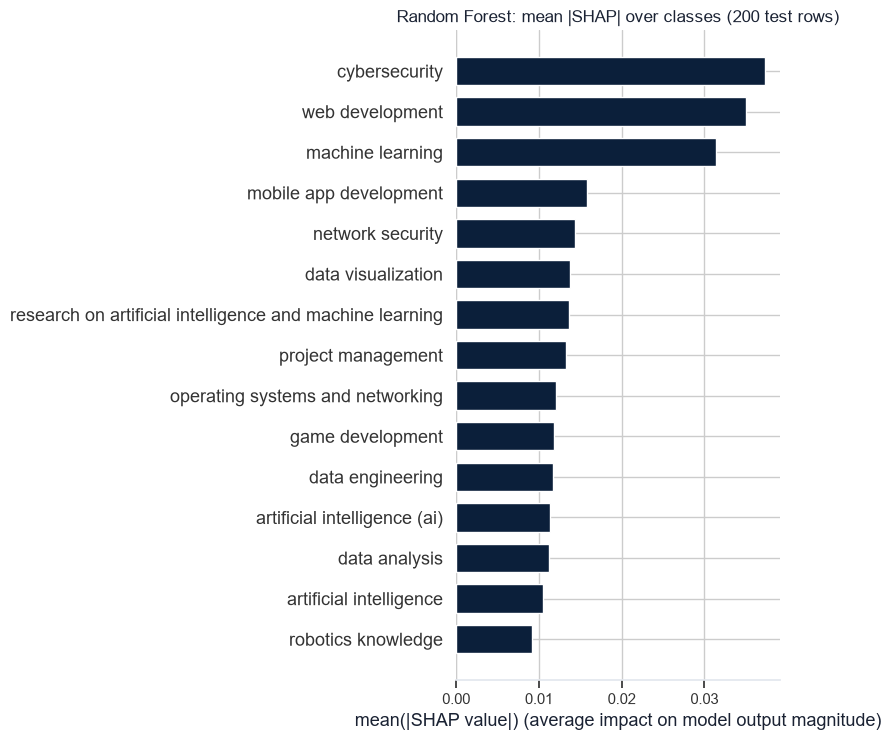

saved artifacts/figures/shap_summary.png
SHAP: ok (2s)


In [13]:
# Optional SHAP summary (spec: optional). Skipped with a note if it fails or is too slow.
shap_note = "not run"
try:
    import shap
    t = time.time()
    sample = Xt_test[:200]
    explainer = shap.TreeExplainer(rf_model[-1])
    sv = explainer.shap_values(sample)
    sv_abs = np.mean([np.abs(s) for s in (sv if isinstance(sv, list) else np.moveaxis(sv, -1, 0))], axis=0)
    shap.summary_plot(sv_abs, sample, feature_names=[n.removeprefix("skill__") for n in rf_model[:-1].get_feature_names_out()],
                      plot_type="bar", max_display=15, show=False, color=NAVY)
    plt.title("Random Forest: mean |SHAP| over classes (200 test rows)")
    savefig("shap_summary.png")
    shap_note = f"ok ({time.time() - t:.0f}s)"
except Exception as exc:
    shap_note = f"skipped: {type(exc).__name__}: {exc}"
print("SHAP:", shap_note)

### Confidence and model scope (D-021)

The model only knows 6 computer-science career fields and the skills in its training vocabulary. Before trusting a prediction we check **how accurate it really is at each confidence level** on the held-out test set. These buckets are what the scope thresholds (`min_confidence`, `min_known_skills`, `min_coverage`) are judged against.

Test-set accuracy by model confidence:


,rows,accuracy
bucket,,
<0.4,27,0.519
0.4-0.5,33,0.667
0.5-0.6,65,0.846
0.6-0.8,167,0.964
>=0.8,82,0.988


Test-set accuracy by number of skills the model knows:


,rows,accuracy
known_bucket,,
0,0,NaN
1,10,0.700
2,33,0.818
3+,331,0.903


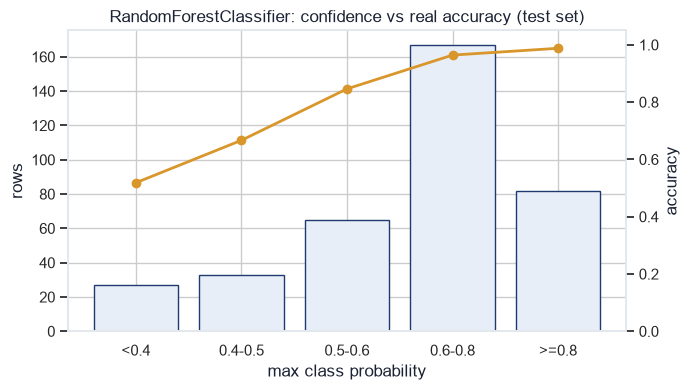

saved artifacts/figures/confidence_vs_accuracy.png
Threshold min_confidence=0.5: confident rows 314 (accuracy 0.946) | low-confidence rows 60 (accuracy 0.600)


In [14]:
from ml_core.job_role import ScopeThresholds, build_feature_schema

proba = best_model.predict_proba(X_test)
conf = proba.max(axis=1)
correct = best_model.classes_[proba.argmax(axis=1)] == y_test
model_vocab = set(best_model.named_steps["skills"].vocabulary_)
n_known = np.array([len(set(x) & model_vocab) for x in X_test])

conf_df = pd.DataFrame({"confidence": conf, "correct": correct, "known": n_known})
conf_df["bucket"] = pd.cut(conf_df["confidence"], [0, 0.4, 0.5, 0.6, 0.8, 1.0001], right=False,
                           labels=["<0.4", "0.4-0.5", "0.5-0.6", "0.6-0.8", ">=0.8"])
by_conf = conf_df.groupby("bucket", observed=False).agg(rows=("correct", "size"), accuracy=("correct", "mean"))
conf_df["known_bucket"] = pd.cut(conf_df["known"], [0, 1, 2, 3, 1000], right=False, labels=["0", "1", "2", "3+"])
by_known = conf_df.groupby("known_bucket", observed=False).agg(rows=("correct", "size"), accuracy=("correct", "mean"))
print("Test-set accuracy by model confidence:"); display(by_conf.round(3))
print("Test-set accuracy by number of skills the model knows:"); display(by_known.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(by_conf.index.astype(str), by_conf["rows"], color=NAVY1, edgecolor=NAVY6, label="test rows")
ax2 = ax.twinx(); ax2.plot(by_conf.index.astype(str), by_conf["accuracy"], color=AMBER, marker="o", lw=2, label="accuracy")
ax2.set_ylim(0, 1.05); ax2.grid(False); ax.set_xlabel("max class probability"); ax.set_ylabel("rows"); ax2.set_ylabel("accuracy")
ax.set_title(f"{best_name}: confidence vs real accuracy (test set)")
savefig("confidence_vs_accuracy.png")

SCOPE = ScopeThresholds()   # defaults 2 / 0.5 / 0.5; reviewed against the tables above and logged in D-021
above = conf_df[conf_df["confidence"] >= SCOPE.min_confidence]
below = conf_df[conf_df["confidence"] < SCOPE.min_confidence]
print(f"Threshold min_confidence={SCOPE.min_confidence}: confident rows {len(above)} (accuracy {above['correct'].mean():.3f}) | "
      f"low-confidence rows {len(below)} (accuracy {below['correct'].mean() if len(below) else float('nan'):.3f})")

In [15]:
import joblib

joblib.dump(searches["DecisionTreeClassifier"].best_estimator_, ART / "models" / "dt.joblib")
joblib.dump(rf_model, ART / "models" / "rf.joblib")
joblib.dump(best_model, ART / "models" / "best_model.joblib")
joblib.dump(best_model.named_steps["skills"], ART / "models" / "preprocess.joblib")
schema = build_feature_schema(best_model.named_steps["skills"], list(best_model.classes_), SCOPE)
(ART / "config" / "feature_schema.json").write_text(json.dumps(schema, indent=2), encoding="utf-8")
for name, fname in (("DecisionTreeClassifier", "classification_report_dt.txt"), ("RandomForestClassifier", "classification_report_rf.txt")):
    (ART / "metrics" / fname).write_text(reports[name], encoding="utf-8")

metrics_out = {
    "generated_by": "notebooks/eligo_engine.ipynb",
    "dataset": {"name": "Student Career Dataset v2 (Mendeley 10.17632/4spj4mbpjr.2)", "rows_raw": n_raw,
                "rows_after_exact_dedup": n_exact, "rows_used": len(jobs), "train": len(X_train), "test": len(X_test),
                "class_counts": jobs["career"].value_counts().to_dict()},
    "models": {n: {k: (float(v) if isinstance(v, (float, np.floating)) else v) for k, v in m.items()} for n, m in metrics.items()},
    "best_model": best_name,
    "selection_rule": "highest test macro-F1 (tie -> RandomForestClassifier)",
    "confusion_matrices": {n: {"labels": classes, "matrix": cms[n].tolist()} for n in cms},
    "feature_importance_rf_top15": rf_top,
    "permutation_importance_top15": perm_top,
    "shap": shap_note,
    "confidence_by_bucket": {str(k): {"rows": int(v.rows), "accuracy": None if pd.isna(v.accuracy) else float(v.accuracy)}
                             for k, v in by_conf.iterrows()},
    "accuracy_by_known_skills": {str(k): {"rows": int(v.rows), "accuracy": None if pd.isna(v.accuracy) else float(v.accuracy)}
                                 for k, v in by_known.iterrows()},
    "scope_thresholds": schema["scope"],
}
(ART / "metrics" / "metrics.json").write_text(json.dumps(metrics_out, indent=2, default=str), encoding="utf-8")
print("saved models, feature_schema.json, metrics.json, classification reports")

saved models, feature_schema.json, metrics.json, classification reports


## 3.4 Hybrid recommendation engine

**Gates first** (`ml_core.eligibility`): status + deadline (imported postings judged against `REFERENCE_DATE` = last scrape day, D-007), qualification hierarchy (D-017), specialisation, academic %, and an assessment score **strictly above 60%**. Only internships that pass every gate are scored:

`final = 0.35 · content (TF-IDF cosine) + 0.40 · semantic (all-MiniLM-L6-v2 cosine, clipped to [0,1]) + 0.25 · skill overlap (|matched| / |required|)`

The TF-IDF vectorizer is fitted on the internship corpus here and only used with `transform` afterwards. The sentence model is pinned to a Hugging Face revision and saved locally for offline use (D-020).

In [16]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, stop_words="english")
tfidf.fit(interns["text"])
joblib.dump(tfidf, ART / "vectorizers" / "tfidf.joblib")
print("TF-IDF vocabulary size:", len(tfidf.vocabulary_))

from sentence_transformers import SentenceTransformer
# Save the pristine pinned model FIRST (encode() writes runtime padding state into tokenizer.json,
# which would make the saved files differ from scripts/setup_sentence_model.py), then encode with
# the copy re-loaded from disk, so the embeddings come from exactly the artifact Django will load.
if C.SENTENCE_MODEL_DIR.exists():
    shutil.rmtree(C.SENTENCE_MODEL_DIR)
SentenceTransformer(C.SENTENCE_MODEL_NAME, revision=C.SENTENCE_MODEL_REVISION, device="cpu") \
    .save(str(C.SENTENCE_MODEL_DIR), create_model_card=False)
print("saved sentence model ->", C.SENTENCE_MODEL_DIR.relative_to(ROOT).as_posix())
st_model = SentenceTransformer(str(C.SENTENCE_MODEL_DIR), device="cpu", local_files_only=True)

t = time.time()
emb = st_model.encode(interns["text"].tolist(), batch_size=64, normalize_embeddings=True,
                      show_progress_bar=False).astype(np.float32)
print(f"Encoded {len(emb):,} internships -> {emb.shape} in {time.time() - t:.0f}s")
np.save(ART / "embeddings" / "internships.npy", emb)
index = [{"source_id": sid, "row": i, "text_hash": hashlib.sha256(txt.encode("utf-8")).hexdigest()}
         for i, (sid, txt) in enumerate(zip(interns["source_id"], interns["text"]))]
(ART / "embeddings" / "internship_index.json").write_text(json.dumps(index), encoding="utf-8")

hybrid = {"weights": {"content": C.DEFAULT_WEIGHTS.content, "semantic": C.DEFAULT_WEIGHTS.semantic,
                      "skill": C.DEFAULT_WEIGHTS.skill},
          "top_n": 10, "version": "1", "reference_date": C.REFERENCE_DATE.isoformat()}
(ART / "config" / "hybrid_config.json").write_text(json.dumps(hybrid, indent=2), encoding="utf-8")

TF-IDF vocabulary size: 13260


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 51156.11it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00, 30.09it/s]

saved sentence model -> artifacts/models/sentence_model


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 51534.45it/s]

Encoded 8,207 internships -> (8207, 384) in 51s


149

### DEMO profiles (illustrative, not training data)

Three hand-written **DEMO** student profiles show the engine's behaviour: a CS student who passed the assessment, a management student who passed, and a student whose assessment score (55%) is not above 60%.

In [17]:
from decimal import Decimal
from ml_core.eligibility import StudentFacts, InternshipFacts
from ml_core.preprocessing import build_student_text
from ml_core.skills import normalise_skills
from ml_core.recommender import recommend

DEMO_PROFILES = {
    "DEMO – B.Tech CSE (Python/ML)": dict(qualification="B.Tech", specialization="CSE", academic_percentage=Decimal("78"),
        skills="Python, Machine Learning, SQL, Data Analysis", interests="AI and data science", role="Data Scientist",
        assessment=Decimal("72.5")),
    "DEMO – BBA (marketing)": dict(qualification="BBA", specialization="Management", academic_percentage=Decimal("68"),
        skills="Digital Marketing, Social Media Marketing, Content Writing, Canva", interests="brand marketing",
        role="Marketing Executive", assessment=Decimal("66")),
    "DEMO – B.Sc (scored 55%)": dict(qualification="B.Sc", specialization="Science", academic_percentage=Decimal("70"),
        skills="MS-Excel, Data Entry", interests="operations", role="Analyst", assessment=Decimal("55")),
}

def student_facts(p):
    skills = tuple(normalise_skills(p["skills"], vocab))
    text = build_student_text(skills, p["interests"], p["role"], p["specialization"])
    return StudentFacts(p["qualification"], p["specialization"], p["academic_percentage"], skills, text)

def internship_facts(row):
    return InternshipFacts(id=row.source_id, status="ACTIVE", deadline=row.application_deadline,
                           required_qualification=row.required_qualification, specialization=row.specialization,
                           minimum_academic_percentage=Decimal(str(row.minimum_academic_percentage)),
                           required_skills=tuple(row.required_skills), text=row.text)

ALL_FACTS = [internship_facts(r) for r in interns.itertuples()]
titles = dict(zip(interns["source_id"], interns["internship_title"] + " @ " + interns["company_name"]))

def run(name, weights=C.DEFAULT_WEIGHTS, top_n=10):
    p = DEMO_PROFILES[name]
    sf = student_facts(p)
    svec = st_model.encode([sf.text], normalize_embeddings=True)[0]
    return sf, recommend(sf, ALL_FACTS, p["assessment"], vectorizer=tfidf, internship_vecs=emb, student_vec=svec,
                         weights=weights, today=C.REFERENCE_DATE, top_n=top_n)

results = {}
for name in DEMO_PROFILES:
    sf, r = run(name)
    results[name] = r
    print(f"\n### {name}\n  normalised skills: {list(sf.skills)}")
    print(f"  eligible internships ranked: {len(r.eligible)} | not eligible: {len(r.not_eligible):,}")
    reasons = Counter(res.failed[0].gate for _, res in r.not_eligible)
    print("  first failed gate among not-eligible:", dict(reasons))
    if r.eligible:
        display(pd.DataFrame([{"rank": x.rank, "internship": titles[x.internship_id], "final": round(x.scores.final, 3),
                               "content": round(x.scores.content, 3), "semantic": round(x.scores.semantic, 3),
                               "skill": round(x.scores.skill, 3), "matched": ", ".join(x.matched),
                               "missing": ", ".join(x.missing)} for x in r.eligible]))


### DEMO – B.Tech CSE (Python/ML)
  normalised skills: ['data analysis', 'machine learning', 'python', 'sql']
  eligible internships ranked: 10 | not eligible: 154
  first failed gate among not-eligible: {'qualification': 154}


,rank,internship,final,content,semantic,skill,matched,missing
0,1,AI & Data Science @ Nutrail Cognitive Analytic...,0.580,0.471,0.726,0.5,"python, sql","data science, database testing"
1,2,Generative AI Machine Learning @ Arakoo,0.575,0.335,0.519,1.0,python,
2,3,Machine Learning @ CareerNest,0.552,0.442,0.681,0.5,python,data science
3,4,AI/ML Developer @ Yardstick,0.541,0.073,0.664,1.0,python,
4,5,Python Development @ Tax-O-Smart LLP,0.520,0.061,0.623,1.0,python,
5,6,Content Developer @ KS Analytical Consulting,0.514,0.375,0.644,0.5,"data analysis, python, sql","data analytics, data science, power bi"
6,7,Data Science Mentor @ DevTown,0.510,0.381,0.629,0.5,"data analysis, python, sql","english proficiency (spoken), english proficie..."
7,8,Automation @ Pilgrim,0.506,0.069,0.580,1.0,python,
8,9,Artificial Intelligence (AI) @ Kunal Kapur,0.504,0.070,0.574,1.0,python,
9,10,Data Science @ Tisteps Private Limited,0.494,0.333,0.693,0.4,"python, sql","artificial intelligence, data analytics, data ..."



### DEMO – BBA (marketing)
  normalised skills: ['canva', 'content writing', 'digital marketing', 'social media marketing']
  eligible internships ranked: 10 | not eligible: 268
  first failed gate among not-eligible: {'qualification': 177, 'specialization': 91}


,rank,internship,final,content,semantic,skill,matched,missing
0,1,Content and Social Media Marketing @ Ranklity ...,0.700,0.403,0.772,1.000,"canva, content writing, social media marketing",
1,2,Content and Social Media Marketing @ Cabin & Co,0.672,0.363,0.737,1.000,canva,
2,3,Content and Social Media Marketing @ Make-up D...,0.656,0.319,0.735,1.000,canva,
3,4,Social Media Marketing @ Flybed Home,0.637,0.427,0.750,0.750,"canva, digital marketing, social media marketing",content marketing
4,5,Social Media @ Times Internet,0.625,0.227,0.739,1.000,"canva, social media marketing",
5,6,Content and Social Media Marketing @ Dharte,0.619,0.289,0.671,1.000,canva,
6,7,Digital Marketing @ Shristi Sinha,0.611,0.323,0.621,1.000,"digital marketing, social media marketing",
7,8,Content and Social Media Marketing @ Travebrate,0.607,0.281,0.647,1.000,"content writing, social media marketing",
8,9,Marketing @ NeoQuant Solutions Pvt Ltd,0.602,0.359,0.690,0.800,"canva, content writing, digital marketing, soc...",effective communication
9,10,Social Media Marketing @ Eduloid Solutions,0.601,0.422,0.717,0.667,"canva, content writing, digital marketing, soc...","video making, videography"



### DEMO – B.Sc (scored 55%)
  normalised skills: ['data entry', 'excel']
  eligible internships ranked: 0 | not eligible: 8,207
  first failed gate among not-eligible: {'assessment': 7933, 'qualification': 183, 'specialization': 91}


In [18]:
from ml_core.config import HybridWeights
WEIGHT_SETS = {"default 0.35/0.40/0.25": C.DEFAULT_WEIGHTS, "content-heavy 0.50/0.30/0.20": HybridWeights(0.5, 0.3, 0.2),
               "semantic-heavy 0.20/0.50/0.30": HybridWeights(0.2, 0.5, 0.3), "equal 0.33/0.33/0.34": HybridWeights(0.33, 0.33, 0.34)}
rows = []
for profile in ("DEMO – B.Tech CSE (Python/ML)", "DEMO – BBA (marketing)"):
    base_top5 = [x.internship_id for x in results[profile].eligible[:5]]
    for label, w in WEIGHT_SETS.items():
        top5 = [x.internship_id for x in run(profile, w, top_n=5)[1].eligible]
        rows.append({"profile": profile, "weights": label, "top-5 overlap with default": len(set(top5) & set(base_top5)),
                     "same #1": top5[:1] == base_top5[:1], "top-5": " | ".join(titles[i][:38] for i in top5)})
print("Weight sensitivity on DEMO profiles (no relevance labels exist, so this shows stability, not accuracy):")
display(pd.DataFrame(rows))

Weight sensitivity on DEMO profiles (no relevance labels exist, so this shows stability, not accuracy):


,profile,weights,top-5 overlap with default,same #1,top-5
0,DEMO – B.Tech CSE (Python/ML),default 0.35/0.40/0.25,5,True,AI & Data Science @ Nutrail Cognitive | Gener...
1,DEMO – B.Tech CSE (Python/ML),content-heavy 0.50/0.30/0.20,3,True,AI & Data Science @ Nutrail Cognitive | Machi...
2,DEMO – B.Tech CSE (Python/ML),semantic-heavy 0.20/0.50/0.30,4,False,AI/ML Developer @ Yardstick | Generative AI Ma...
3,DEMO – B.Tech CSE (Python/ML),equal 0.33/0.33/0.34,4,False,Generative AI Machine Learning @ Arako | AI/ML...
4,DEMO – BBA (marketing),default 0.35/0.40/0.25,5,True,Content and Social Media Marketing @ R | Conte...
5,DEMO – BBA (marketing),content-heavy 0.50/0.30/0.20,4,True,Content and Social Media Marketing @ R | Conte...
6,DEMO – BBA (marketing),semantic-heavy 0.20/0.50/0.30,4,True,Content and Social Media Marketing @ R | Conte...
7,DEMO – BBA (marketing),equal 0.33/0.33/0.34,4,True,Content and Social Media Marketing @ R | Conte...


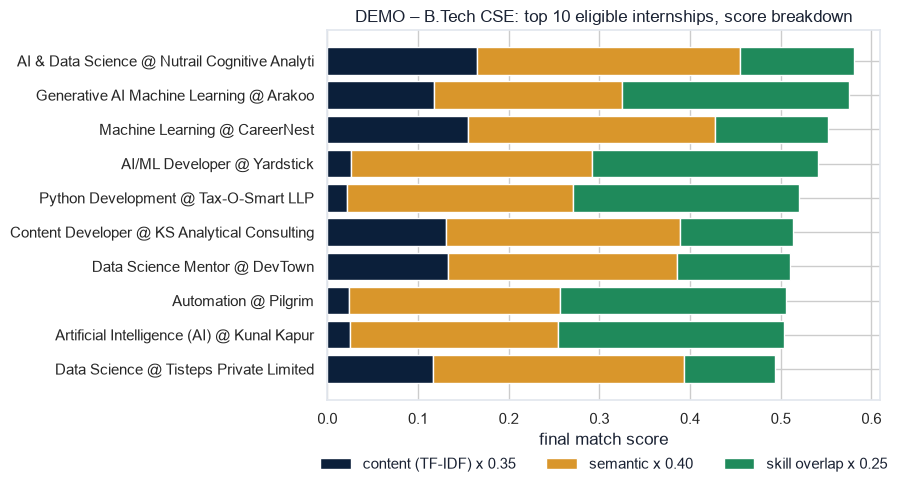

saved artifacts/figures/similarity_ranking_demo.png


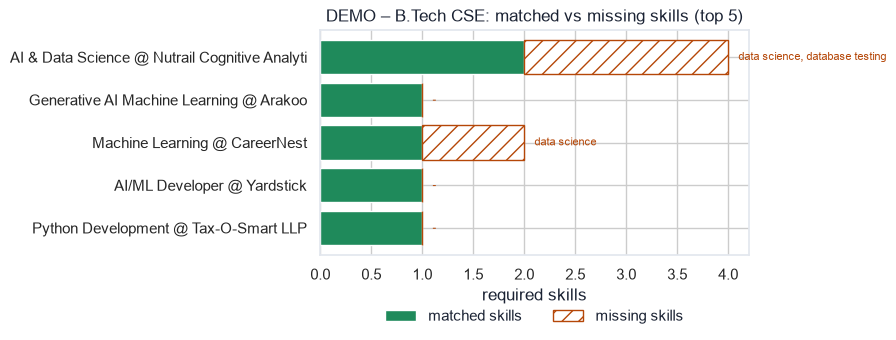

saved artifacts/figures/skill_match_demo.png


In [19]:
demo = results["DEMO – B.Tech CSE (Python/ML)"].eligible[:10]
labels = [titles[x.internship_id][:45] for x in demo][::-1]
c = np.array([x.scores.contributions["content"] for x in demo][::-1])
s = np.array([x.scores.contributions["semantic"] for x in demo][::-1])
k = np.array([x.scores.contributions["skill"] for x in demo][::-1])
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(labels, c, color=NAVY, label="content (TF-IDF) x 0.35")
ax.barh(labels, s, left=c, color=AMBER, label="semantic x 0.40")
ax.barh(labels, k, left=c + s, color=GREEN, label="skill overlap x 0.25")
ax.set_xlabel("final match score"); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False)
ax.set_title("DEMO – B.Tech CSE: top 10 eligible internships, score breakdown")
savefig("similarity_ranking_demo.png")

top5 = demo[:5]
fig, ax = plt.subplots(figsize=(9, 3.6))
lab = [titles[x.internship_id][:45] for x in top5][::-1]
m = [len(x.matched) for x in top5][::-1]; miss = [len(x.missing) for x in top5][::-1]
ax.barh(lab, m, color=GREEN, label="matched skills")
ax.barh(lab, miss, left=m, color="white", edgecolor=ORANGE, hatch="//", label="missing skills")
for i, x in enumerate(top5[::-1]):
    ax.text(len(x.matched) + len(x.missing) + 0.1, i, ", ".join(x.missing[:3]) or "-", va="center", fontsize=8, color=ORANGE)
ax.set_xlabel("required skills"); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=False)
ax.set_title("DEMO – B.Tech CSE: matched vs missing skills (top 5)")
savefig("skill_match_demo.png")

## 3.5 LLM skill analysis (optional, local Ollama) with rule-based fallback

`ml_core.llm_extract` calls `POST /api/chat` on a local Ollama with a JSON-schema `format`, `think: false`, temperature 0 and a 20 s timeout, validates the answer with pydantic, retries once, and otherwise falls back to the deterministic rule-based extractor. The result always says which method produced it. No RAG, no vector database.

In [20]:
from ml_core.llm_extract import LLMConfig, extract_skills, analyse_gap, ollama_available
import requests

llm_cfg = LLMConfig()
llm_cfg.to_json(ART / "config" / "llm_config.json")

def model_installed(cfg):
    try:
        return any(m.get("name", "").startswith(cfg.model)
                   for m in requests.get(f"{cfg.base_url}/api/tags", timeout=2).json().get("models", []))
    except Exception:
        return False

llm_on = ollama_available(llm_cfg) and model_installed(llm_cfg)
print(f"Ollama + {llm_cfg.model} available: {llm_on}")
sample = interns[interns["required_skills"].map(len) >= 3].iloc[0]
print("\nInternship text:", sample.description)
rb = extract_skills(sample.description, vocab=vocab, config=llm_cfg, use_llm=False)
print("\nrule_based ->", rb.skills, "|", rb.detail)
if llm_on:
    t = time.time()
    lm = extract_skills(sample.description, vocab=vocab, config=llm_cfg)
    print(f"{lm.method} ({time.time() - t:.1f}s) ->", lm.skills, "|", lm.detail)
else:
    print("NOTE: Ollama or the model isn't available, so only the rule-based path ran (PENDING - Ollama for the live output).")
gap = analyse_gap(list(student_facts(DEMO_PROFILES["DEMO – B.Tech CSE (Python/ML)"]).skills), sample.description,
                  vocab=vocab, config=llm_cfg, use_llm=llm_on)
print(f"\nSkill gap for DEMO – B.Tech CSE vs this internship ({gap.method}): matched {gap.matched}, missing {gap.missing}")

Ollama + qwen3:4b available: False

Internship text: Marketing internship at Arbhu Enterprises Private Limited. Required skills: digital marketing, english proficiency (spoken), english proficiency (written), ms office, social media marketing.

rule_based -> ['digital marketing', 'english proficiency (spoken)', 'english proficiency (written)', 'marketing', 'ms office', 'social media marketing'] | Rule-based extraction (LLM not used).
NOTE: Ollama or the model isn't available, so only the rule-based path ran (PENDING - Ollama for the live output).

Skill gap for DEMO – B.Tech CSE vs this internship (rule_based): matched [], missing ['digital marketing', 'english proficiency (spoken)', 'english proficiency (written)', 'marketing', 'ms office', 'social media marketing']


## 3.6 Explainable AI

`ml_core.explain` turns computed values into an explanation: each gate's result and reason, the assessment score against the 60% threshold, matched and missing skills, every score component × its weight = its contribution, the final score and rank, plus a template sentence filled with those numbers only.

In [21]:
from ml_core.explain import explain_recommendation, explain_ineligible

r = results["DEMO – B.Tech CSE (Python/ML)"]
for item in r.eligible[:3]:
    e = explain_recommendation(item, r.weights, r.assessment_score)
    print(f"#{e['rank']} {titles[item.internship_id]}")
    print("  ", e["sentence"])
    print("   components:", [(c["name"], round(c["score"], 3), c["weight"], round(c["contribution"], 3)) for c in e["components"]])
    print("   assessment:", e["assessment"])
iid, res = r.not_eligible[0]
print(f"\nWhy DEMO – B.Tech CSE can't apply to '{titles[iid]}':", explain_ineligible(res))
iid, res = results["DEMO – B.Sc (scored 55%)"].not_eligible[0]
print(f"Why DEMO – B.Sc (55%) can't apply to '{titles[iid]}':", explain_ineligible(res))

#1 AI & Data Science @ Nutrail Cognitive Analytics Private Limited
   Ranked #1 with a 58% match. You match 2 of 4 required skills (python, sql). The largest part of the score came from semantic (sentence-transformer) similarity (+0.29).
   components: [('content', 0.471, 0.35, 0.165), ('semantic', 0.726, 0.4, 0.29), ('skill', 0.5, 0.25, 0.125)]
   assessment: {'score': '72.50%', 'threshold': '60%', 'passed': True}
#2 Generative AI Machine Learning @ Arakoo
   Ranked #2 with a 58% match. You match 1 of 1 required skills (python). The largest part of the score came from skill overlap (+0.25).
   components: [('content', 0.335, 0.35, 0.117), ('semantic', 0.519, 0.4, 0.208), ('skill', 1.0, 0.25, 0.25)]
   assessment: {'score': '72.50%', 'threshold': '60%', 'passed': True}
#3 Machine Learning @ CareerNest
   Ranked #3 with a 55% match. You match 1 of 2 required skills (python). The largest part of the score came from semantic (sentence-transformer) similarity (+0.27).
   components: [('con

## 3.7 Save the manifest, then reload everything from disk

`write_manifest` records the SHA-256 of every artifact (the sentence-model weights included, its model card excluded), library versions, the best model and the pinned sentence-model revision. Then all in-memory models are deleted and everything is reloaded through `ml_core.artifacts.load_bundle()` (the same loader Django uses) to prove the saved artifacts work **without retraining**.

In [22]:
from ml_core.artifacts import write_manifest, load_bundle

write_manifest(ART, best_model_name=best_name, model_version="1", sentence_model_revision=C.SENTENCE_MODEL_REVISION,
               extra={"internships": len(interns), "job_role_rows": len(jobs)})
expected_top5 = [x.internship_id for x in results["DEMO – B.Tech CSE (Python/ML)"].eligible[:5]]
del searches, best_model, rf_model, tfidf, st_model, emb

bundle, status = load_bundle()
print(status.message)
assert status.ok, status
print("loaded:", bundle.model_name, "v" + bundle.model_version, "| embeddings", bundle.internship_vecs.shape,
      "| sentence model", type(bundle.sentence_model).__name__)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 6641.56it/s]

AI engine ready.
loaded: RandomForestClassifier v1 | embeddings (8207, 384) | sentence model SentenceTransformer


In [23]:
from ml_core.job_role import predict_job_role
from ml_core.explain import explain_job_role

for name in ("DEMO – B.Tech CSE (Python/ML)", "DEMO – BBA (marketing)"):
    pred = predict_job_role(normalise_skills(DEMO_PROFILES[name]["skills"], bundle.vocab), bundle)
    e = explain_job_role(pred)
    print(f"{name}: label={e['label']} confidence={e['confidence_pct']}% scope={e['scope_status']}")
    print("   known:", e["known_skills"], "| unknown:", e["unknown_skills"])
    print("  ", e["scope_message"] or "(confident prediction)")

p = DEMO_PROFILES["DEMO – B.Tech CSE (Python/ML)"]
sf = student_facts(p)
svec = bundle.sentence_model.encode([sf.text], normalize_embeddings=True)[0]
r2 = recommend(sf, ALL_FACTS, p["assessment"], vectorizer=bundle.vectorizer, internship_vecs=bundle.internship_vecs,
               student_vec=svec, weights=bundle.hybrid.weights, today=C.REFERENCE_DATE, top_n=5)
reloaded_top5 = [x.internship_id for x in r2.eligible]
print("\nTop 5 after reload:", [titles[i] for i in reloaded_top5])
assert reloaded_top5 == expected_top5, "reloaded artifacts changed the ranking"
print("Reload test passed: same ranking from the saved artifacts, nothing retrained.")

DEMO – B.Tech CSE (Python/ML): label=Artificial Intelligence confidence=38% scope=low_confidence
   known: ['data analysis', 'machine learning', 'sql'] | unknown: ['python']
   Low confidence: the model is only 38% sure. It covers 6 computer-science career fields, so treat the closest match as tentative.
DEMO – BBA (marketing): label=Development confidence=33% scope=low_confidence
   known: ['canva', 'digital marketing'] | unknown: ['content writing', 'social media marketing']
   Low confidence: the model is only 33% sure. It covers 6 computer-science career fields, so treat the closest match as tentative.



Top 5 after reload: ['AI & Data Science @ Nutrail Cognitive Analytics Private Limited', 'Generative AI Machine Learning @ Arakoo', 'Machine Learning @ CareerNest', 'AI/ML Developer @ Yardstick', 'Python Development @ Tax-O-Smart LLP']
Reload test passed: same ranking from the saved artifacts, nothing retrained.


**Done.** Artifacts are in `artifacts/` with `manifest.json`. Django loads them read-only through `ml_core.artifacts.load_bundle()`; it never refits a model or the TF-IDF vectorizer. The sentence model folder is git-ignored (~90 MB): after a fresh clone, run `.\.venv\Scripts\python.exe scripts\setup_sentence_model.py` once (or re-run this notebook).